### Carga de los Datos de Boston Housing


In [33]:
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
import pandas as pd

In [59]:
# cargar los datos desde scikit-learn
#from sklearn.datasets import load_boston

#boston = load_boston()
#boston = pd.read_csv("HousingData.csv")
#boston = pd.read_csv("boston.csv")
#boston = pd.read_csv("boston-housing-dataset.csv")
#delitos = pd.read_csv("delitos_puerto_montt_2024.csv")
#delitos = pd.read_csv("delitos_puerto_montt_2024.csv", encoding="latin1")

#print(delitos.keys())
#print(delitos)
#with open("delitos_puerto_montt_2024.csv", 'rb') as f:
#    result = chardet.detect(f.read(10000))
#print(result)
#delitos = pd.read_csv("delitos_puerto_montt_2024.csv", encoding=result['encoding'])

delitos = pd.read_csv("delitos_puerto_montt_2024.csv", encoding="ISO-8859-1", sep=";")
print(delitos.columns.tolist())  # para confirmar que está 'AO'
#delitos = delitos.drop('A¥O', axis=1)
print(delitos.keys())
pd.set_option('display.max_rows', 50)  # ahora se verán todas las filas
print(delitos)


['A¥O', 'MES', '??Femicidio', '??Femicidio no ¡ntimo', '??Suicidio femicida', '??Violaci¢n con homicidio', '??Robo con homicidio', '??Auxilio al suicidio', '??Otros homicidios', '??Tortura o apremios ileg¡timos con violaci¢n', '??Robo con violaci¢n', '??Otras violaciones', '??Abusos sexuales', '??Otros delitos sexuales', '??Robos con violencia o intimidaci¢n', '??Robo violento de veh¡culo motorizado', '??Violencia intrafamiliar a mujer', '??Violencia intrafamiliar a ni¤o o ni¤a', '??Violencia intrafamiliar a adulto mayor', '??Violencia intrafamiliar a hombre', '??Violencia intrafamiliar no clasificada', '??Tr\xa0fico de sustancias', '??Microtr\xa0fico de sustancias', '??Elaboraci¢n o producci¢n de sustancias', '??Otras infracciones a la ley de drogas', '??Disparo injustificado', '??Porte / posesi¢n de armas o explosivos', '??Otras infracciones a la ley de armas', '??Robo en lugar habitado', '??Robos en lugar no habitado', '??Robo de veh¡culo motorizado', '??Robo de objetos de o desde v

In [61]:
delitos_ds = pd.DataFrame(delitos, columns= delitos.keys())
delitos_ds.head()

,A¥O,MES,??Femicidio,??Femicidio no ¡ntimo,??Suicidio femicida,??Violaci¢n con homicidio,??Robo con homicidio,??Auxilio al suicidio,??Otros homicidios,??Tortura o apremios ileg¡timos con violaci¢n,...,??Robos en lugar no habitado,??Robo de veh¡culo motorizado,??Robo de objetos de o desde veh¡culo,??Animales sueltos en la v¡a p£blica,??Comercio ilegal,??Ofensas al pudor,??Otras incivilidades,??Abigeato,??Robo frustrado,??Otros delitos o faltas
0,2005.0,1,0,0,0,0,0,0,5,0,...,131,6,78,3,66,1,68,36,11,892.0
1,NaN,2,0,0,0,0,0,0,0,0,...,137,21,64,9,52,1,73,25,23,866.0
2,NaN,3,0,0,0,0,0,0,2,0,...,147,8,101,7,77,2,75,29,14,938.0
3,NaN,4,0,0,0,0,0,0,5,0,...,173,15,102,16,47,0,86,47,9,908.0
4,NaN,5,0,0,0,0,0,0,2,0,...,230,8,107,7,47,0,59,51,14,905.0


In [62]:
#Eliminar los espacios vacíos y nulos
#delitos_ds.isnull().sum()

###Exploración de los Datos

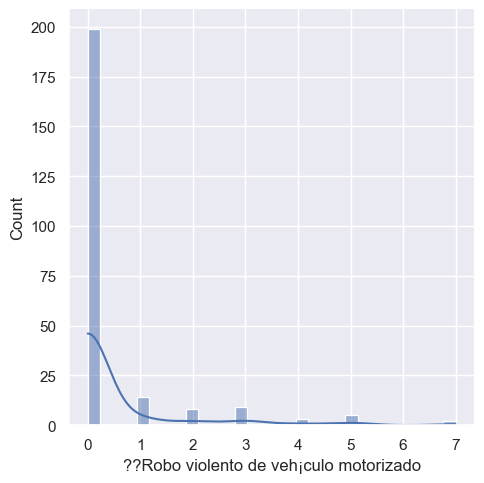

In [66]:
sns.set(rc = {'figure.figsize': (20,10)})
sns.displot(delitos_ds['??Robo violento de veh¡culo motorizado'], bins = 30, kde = True)
plt.show()

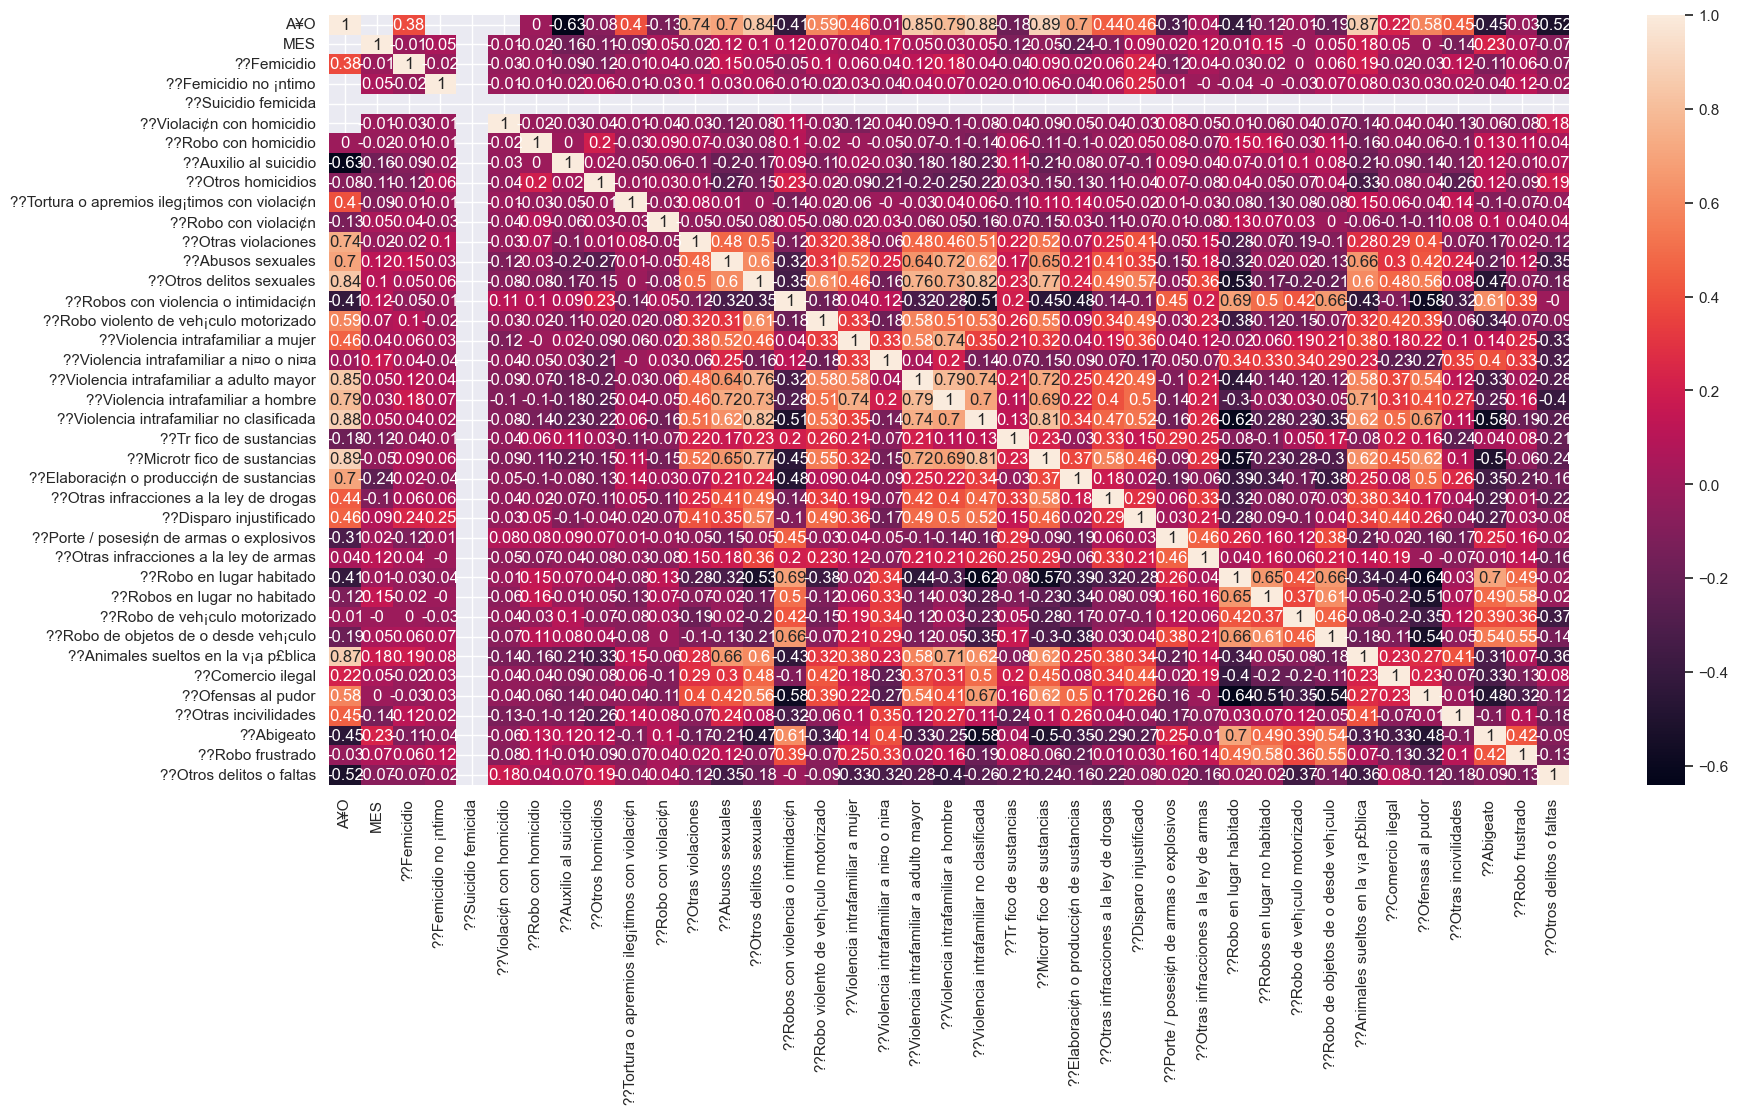

In [67]:
#Matriz de correlación
matriz_corr = delitos_ds.corr().round(2)
#print(matriz_corr)
sns.heatmap(data = matriz_corr, annot=True);

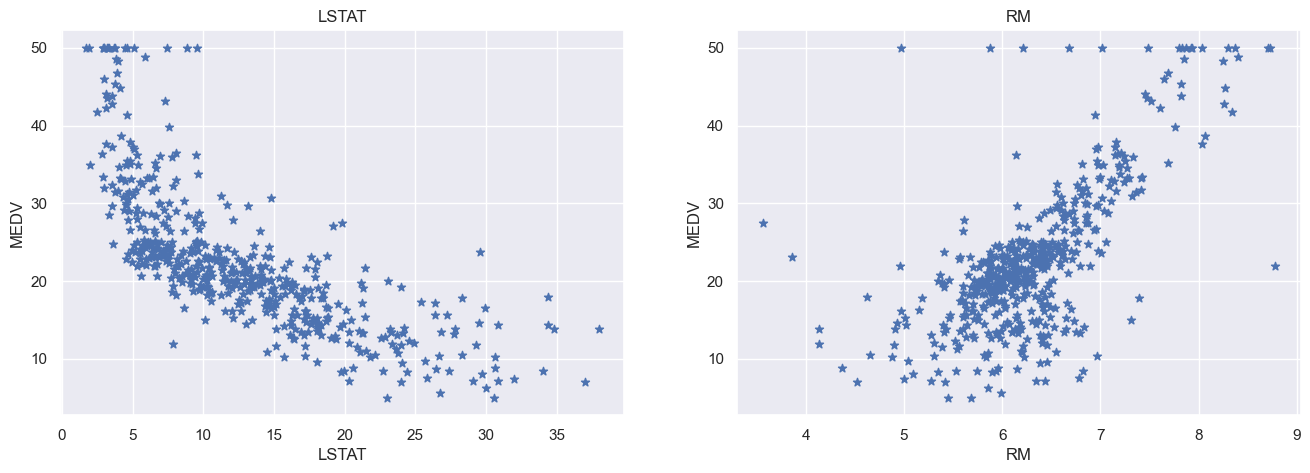

In [33]:
#Graficar LSTAT y RM
plt.figure(figsize= (16,5))

atributos = ['LSTAT', 'RM']
objetivo = boston_ds['MEDV']

for i, col in enumerate(atributos):
  plt.subplot(1, len(atributos), i+1)
  x = boston_ds[col]
  y = objetivo

  plt.scatter(x,y,marker='*')
  plt.title(col)
  plt.xlabel(col)
  plt.ylabel('MEDV')

###Preprocesamiento de Datos

In [34]:
#Dividir los conjuntos en X  e Y (Datos de entrada y Datos de salida)
X = pd.DataFrame(np.c_[boston_ds['LSTAT']], columns=['LSTAT'])
y = boston_ds['MEDV']

In [35]:
# Separar entre los conjuntos de entrenamiento y testeo
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state = 10)

print("Entrenamiento: X = {}, y = {}".format(X_train.shape, y_train.shape))
print("Testeo: X = {}, y = {}".format(X_test.shape, y_test.shape))

Entrenamiento: X = (404, 1), y = (404,)
Testeo: X = (102, 1), y = (102,)


###Crear Modelo

In [36]:
#Creación del modelo de regresión Lineal
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

modelo = LinearRegression() #Hipótesis

In [37]:
#Entrenamiento
modelo.fit(X_train, y_train)

LinearRegression()

In [38]:
# Evaluación del Entrenamiento con el modelo

y_predicted = modelo.predict(X_train)
rmse = np.sqrt(mean_squared_error(y_train, y_predicted))
r2 = r2_score(y_train, y_predicted)

print("Rendimiento del conjunto de Entrenamiento")
print("RMSE: {}".format(rmse))
print("R2: {}".format(r2))

Rendimiento del conjunto de Entrenamiento
RMSE: 5.814319896298229
R2: 0.560733590611812


In [39]:
# Evaluación del Test con el modelo

y_predicted = modelo.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_predicted))
r2 = r2_score(y_test, y_predicted)

print("Rendimiento del conjunto de Testeo")
print("RMSE: {}".format(rmse))
print("R2: {}".format(r2))

Rendimiento del conjunto de Testeo
RMSE: 7.587524204790588
R2: 0.44951123968029405


###Gráficas de Rendimiento

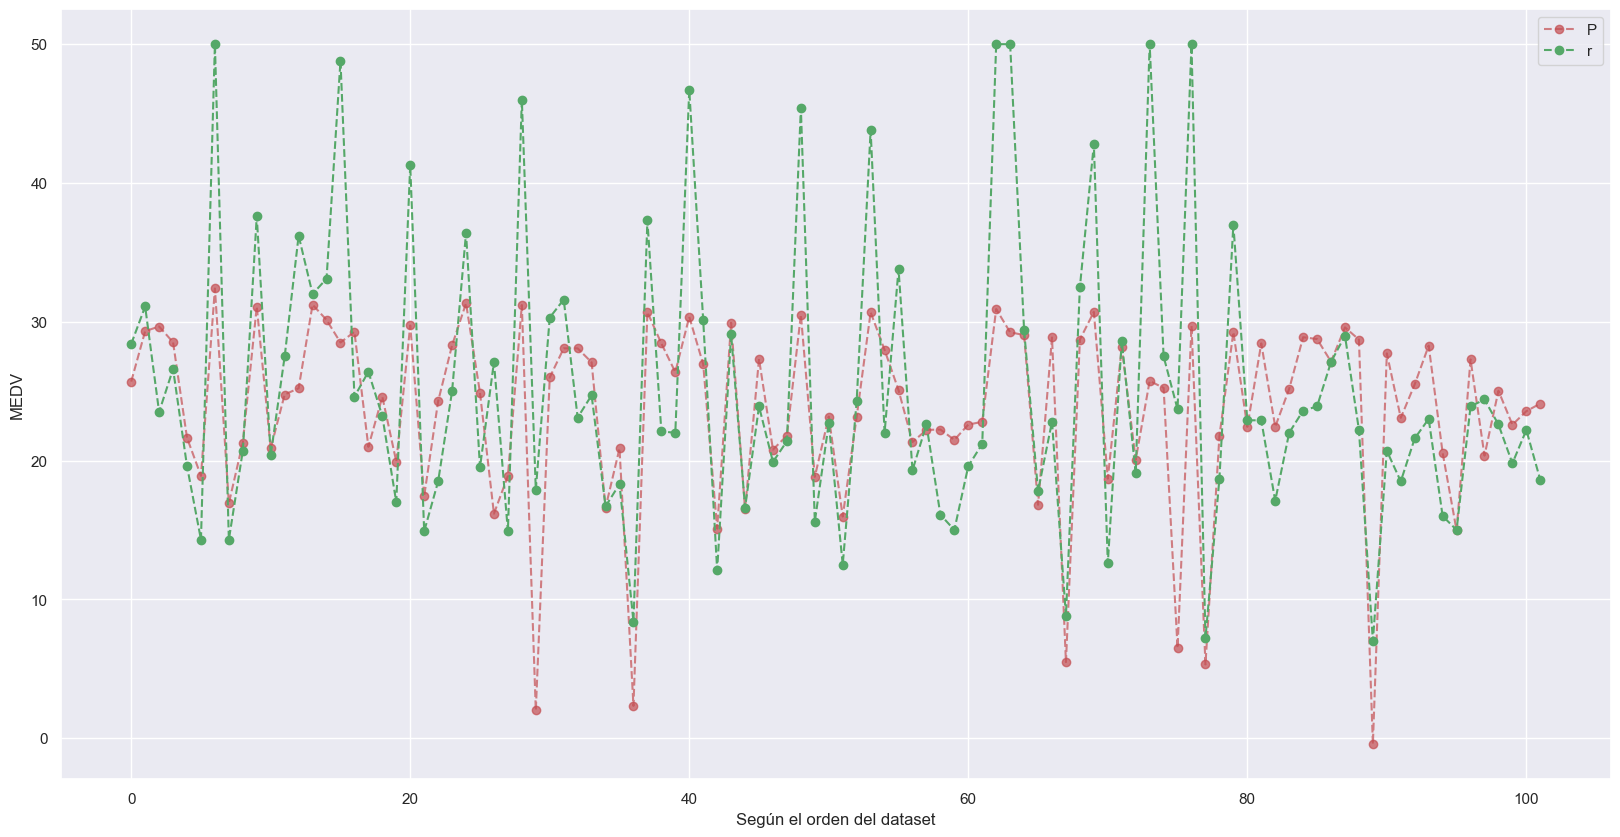

In [40]:
#Gráfica de rendimiento de las predicciones

eje_x = np.array(range(0, y_predicted.shape[0]))

plt.plot(eje_x, y_predicted, linestyle = "--", marker = "o", alpha= 0.7, color= "r", label = "Predicciones")
plt.plot(eje_x, y_test, linestyle = "--", marker = "o", color= "g", label = "y_test")
plt.xlabel("Según el orden del dataset")
plt.ylabel("MEDV")
plt.legend("Predicciones VS Valores Reales")
plt.show()

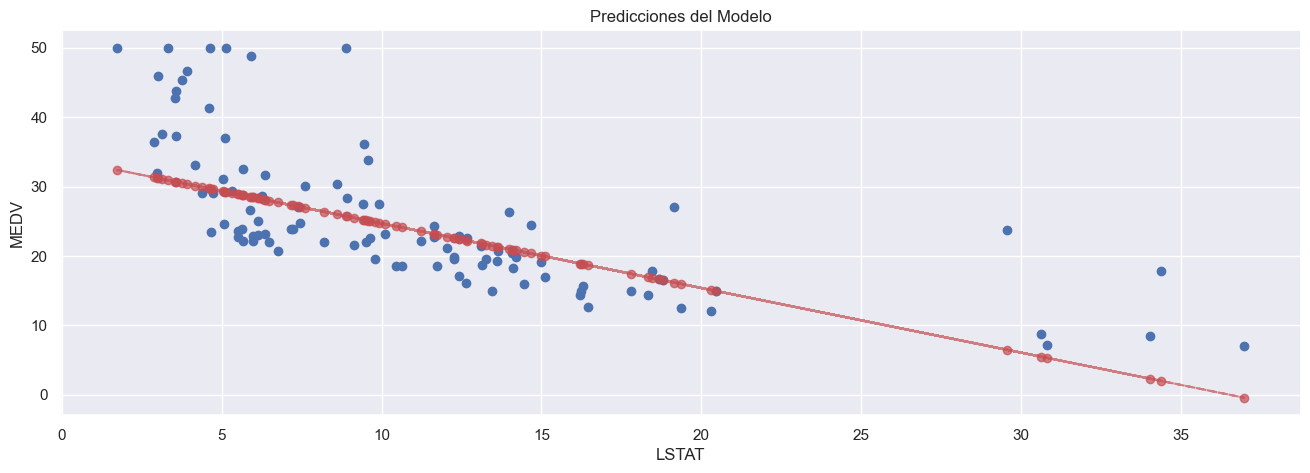

In [41]:
#Gráfica ordenada por el modelo

plt.figure(figsize=(16,5))


plt.plot(X_test, y_predicted, linestyle = "--", marker = "o", alpha= 0.7, color= "r", label = "Predicciones")
plt.scatter(X_test,y_test, marker="o")
plt.title("Predicciones del Modelo")
plt.xlabel("LSTAT")
plt.ylabel("MEDV")
plt.show()

###Comparando con otros modelos (Hipótesis)

In [42]:
def probar_modelo(tipo_hipotesis, X_train, y_train, X_test, y_test):
  modelo = tipo_hipotesis
  modelo.fit(X_train, y_train)

  # Evaluación del Entrenamiento con el modelo

  y_train_predicted = modelo.predict(X_train)
  rmse = np.sqrt(mean_squared_error(y_train, y_train_predicted))
  r2 = r2_score(y_train, y_train_predicted)

  print("Rendimiento del conjunto de Entrenamiento")
  print("RMSE: {}".format(rmse))
  print("R2: {}".format(r2))

  # Evaluación del Test con el modelo

  y_test_predicted = modelo.predict(X_test)
  rmse = np.sqrt(mean_squared_error(y_test, y_test_predicted))
  r2 = r2_score(y_test, y_test_predicted)

  print("Rendimiento del conjunto de Testeo")
  print("RMSE: {}".format(rmse))
  print("R2: {}".format(r2))

  #Gráfica de rendimiento de las predicciones

  eje_x = np.array(range(0, y_test_predicted.shape[0]))

  plt.plot(eje_x, y_test_predicted, linestyle = "--", marker = "o", alpha= 0.7, color= "r", label = "Predicciones")
  plt.plot(eje_x, y_test, linestyle = "--", marker = "o", color= "g", label = "y_test")
  plt.xlabel("Según el orden del dataset")
  plt.ylabel("MEDV")
  plt.legend("Predicciones VS Valores Reales")
  plt.show()

  #Gráfica ordenada por el modelo
  modelo_desordenado = pd.DataFrame(np.c_[X_test, y_test_predicted], columns=['LSTAT','MEDV_'])
  modelo_ordenado = modelo_desordenado.sort_values(by='LSTAT', ascending = True)

  plt.figure(figsize=(16,5))


  plt.plot(modelo_ordenado['LSTAT'], modelo_ordenado['MEDV_'], linestyle = "--", marker = "o", alpha= 0.7, color= "r", label = "Predicciones")
  plt.scatter(X_test,y_test, marker="o")
  plt.title("Predicciones del Modelo")
  plt.xlabel("LSTAT")
  plt.ylabel("MEDV")
  plt.show()

Probando el Modelo Lasso
Rendimiento del conjunto de Entrenamiento
RMSE: 5.816048217625798
R2: 0.5604724056913158
Rendimiento del conjunto de Testeo
RMSE: 7.603166356402437
R2: 0.4472391666574008


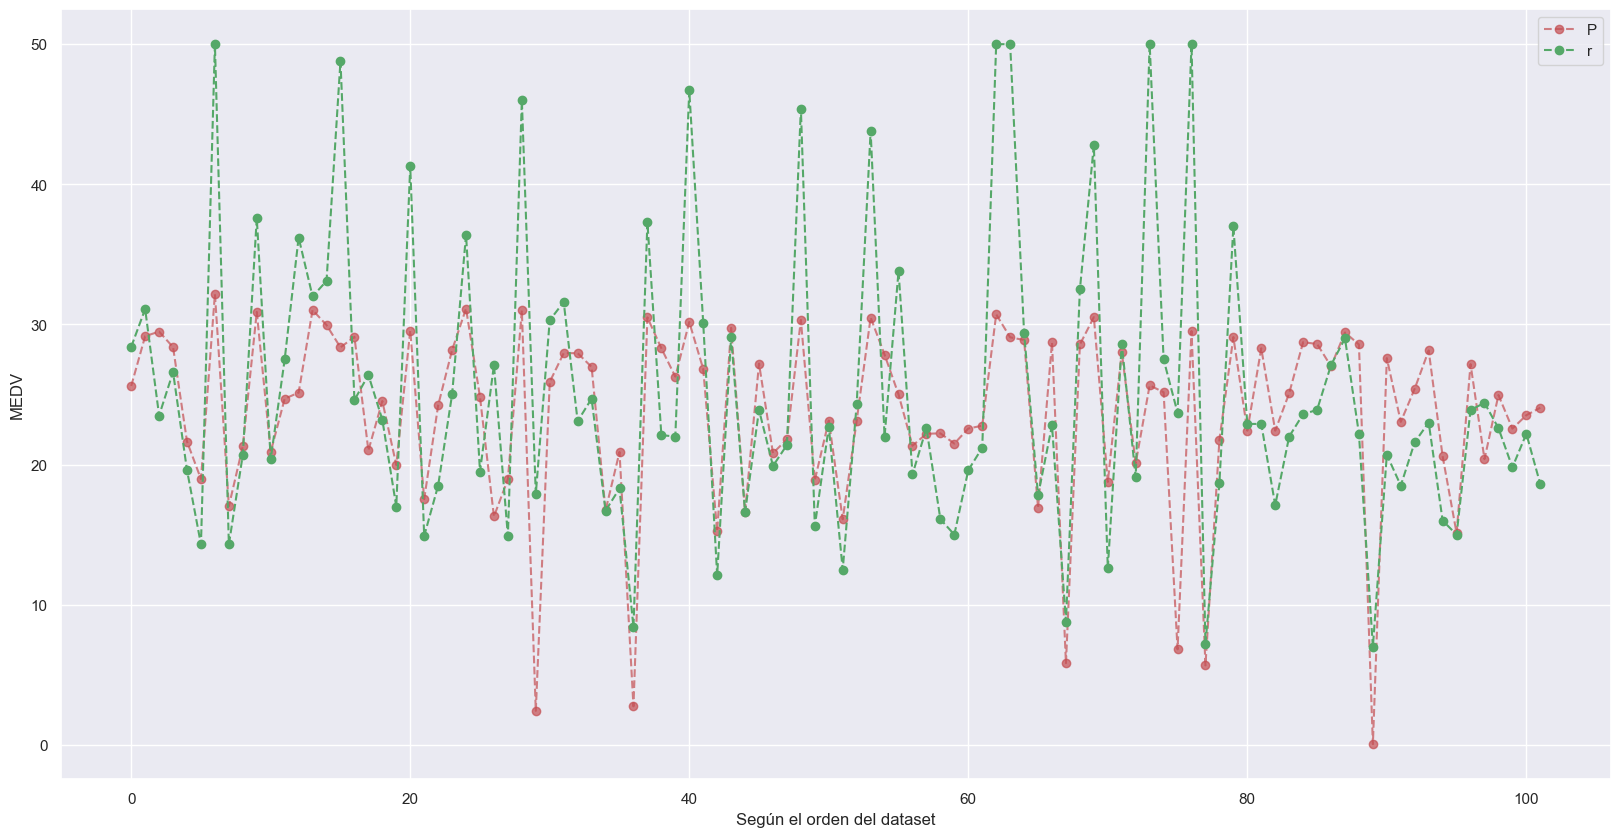

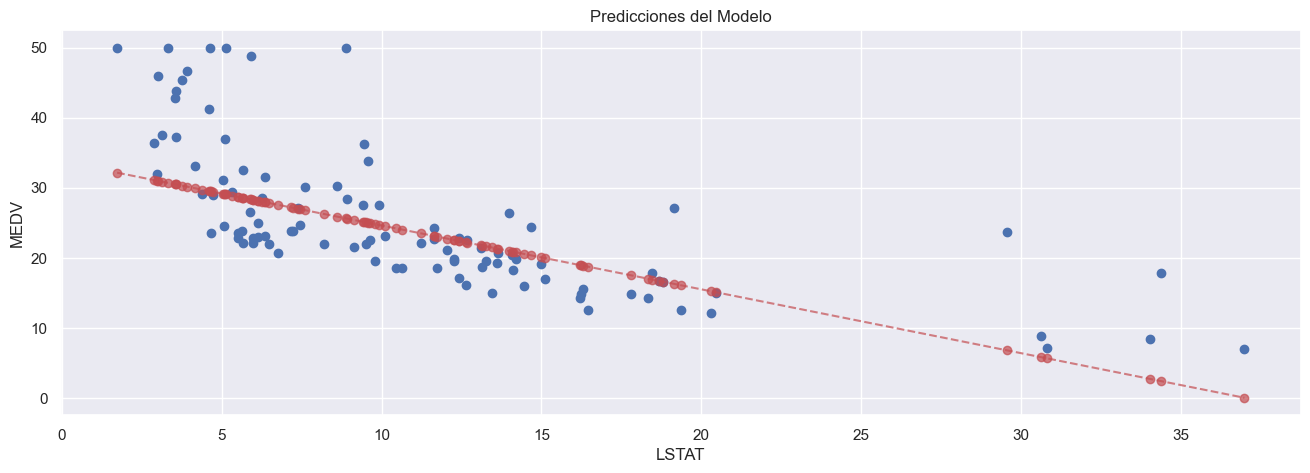

In [43]:
from sklearn.linear_model import Lasso

print("Probando el Modelo Lasso")
probar_modelo(Lasso(), X_train, y_train, X_test, y_test)

Probando el ARD
Rendimiento del conjunto de Entrenamiento
RMSE: 5.814333918927871
R2: 0.5607314718162484
Rendimiento del conjunto de Testeo
RMSE: 7.588811635380868
R2: 0.44932441294286984


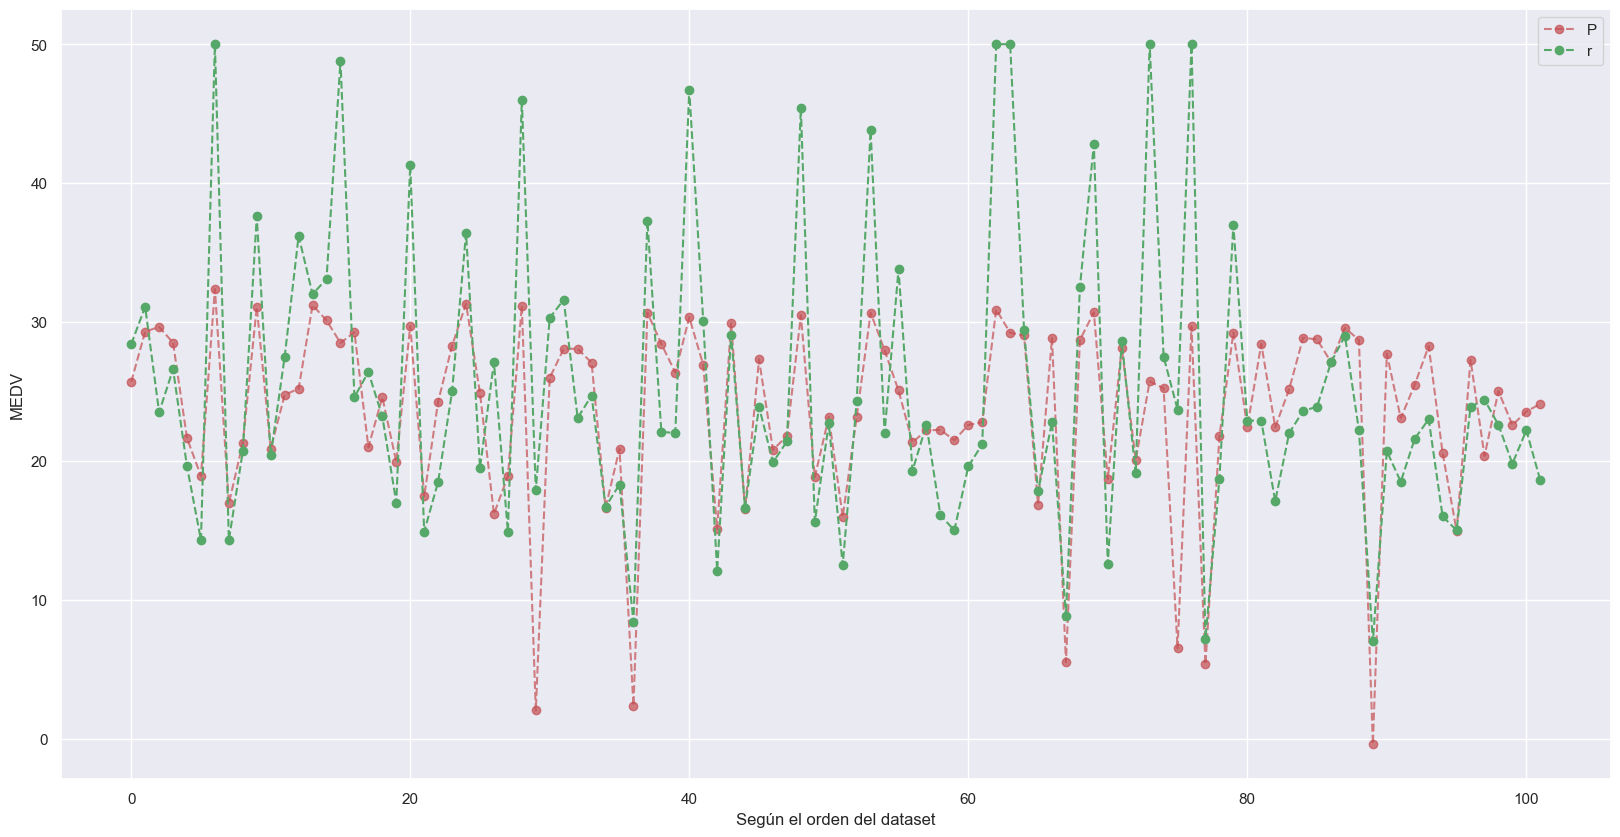

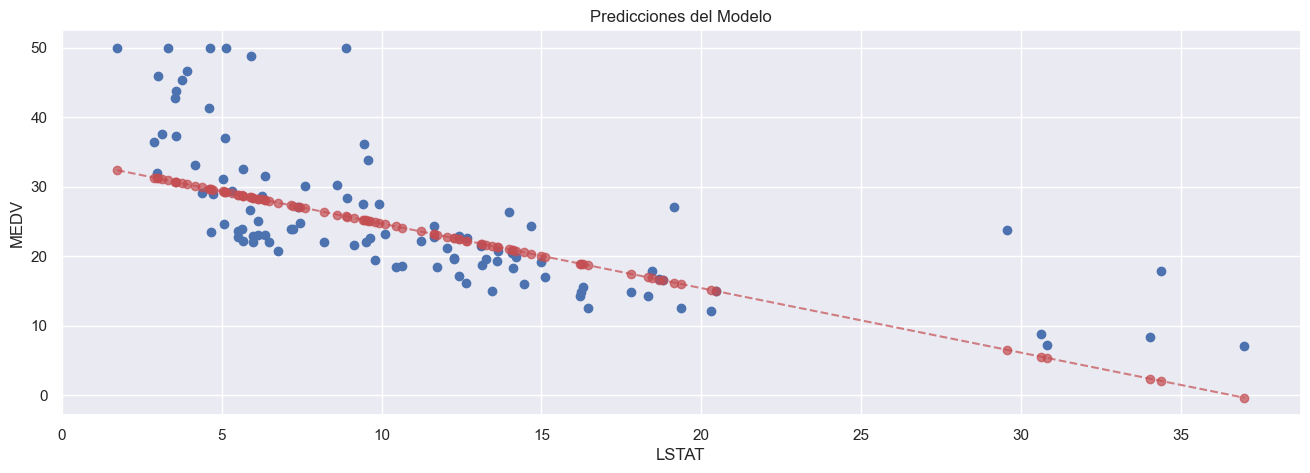

In [44]:
from sklearn.linear_model import ARDRegression

print("Probando el ARD")
probar_modelo(ARDRegression(), X_train, y_train, X_test, y_test)

Probando el SVM
Rendimiento del conjunto de Entrenamiento
RMSE: 5.398326029727825
R2: 0.6213409252056445
Rendimiento del conjunto de Testeo
RMSE: 7.302180370988369
R2: 0.4901371261162589


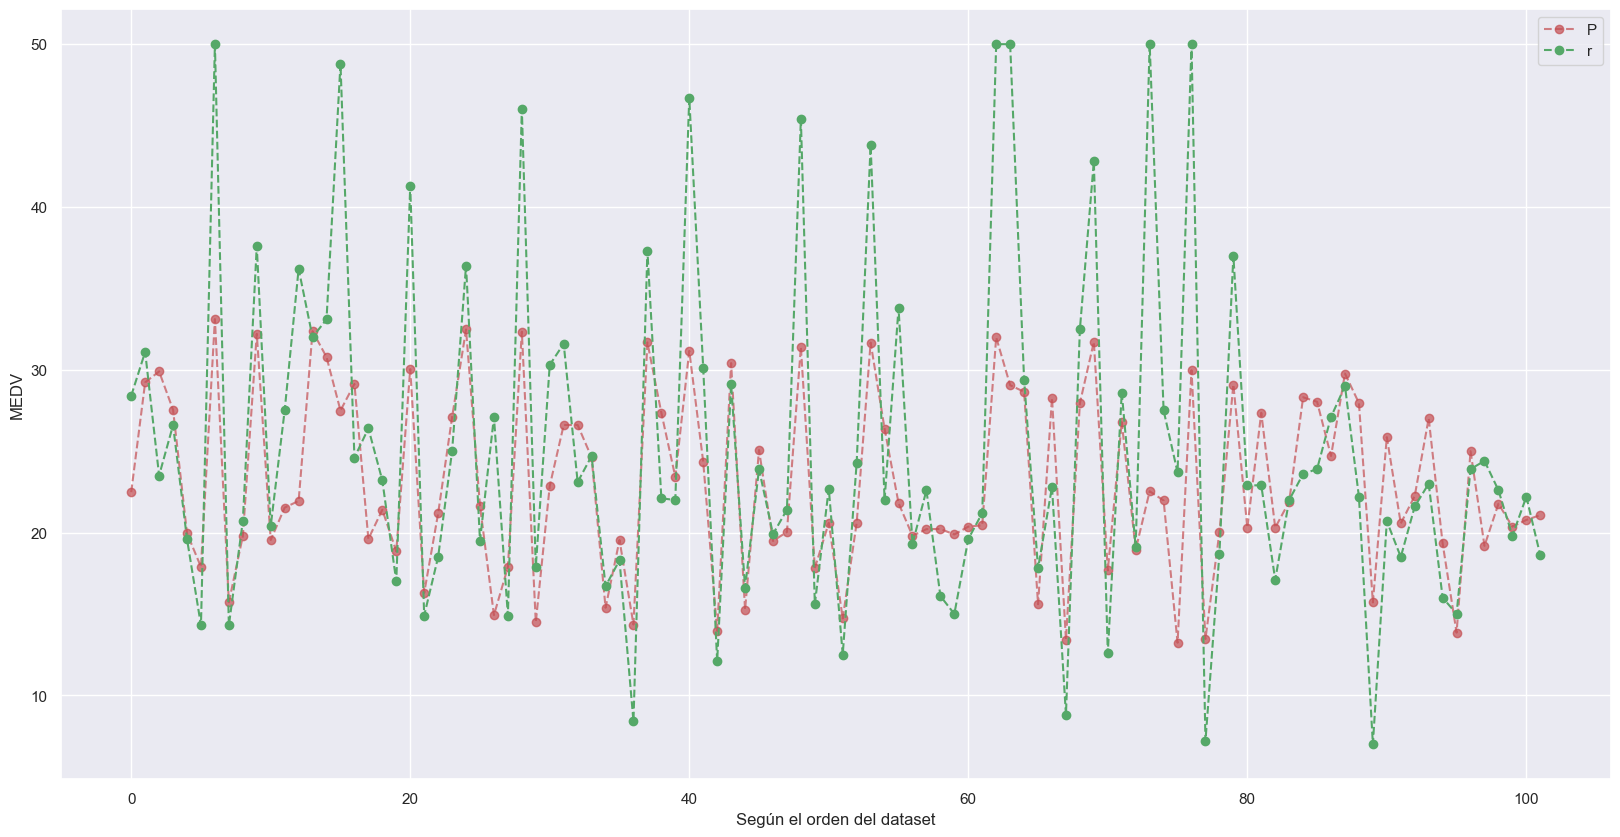

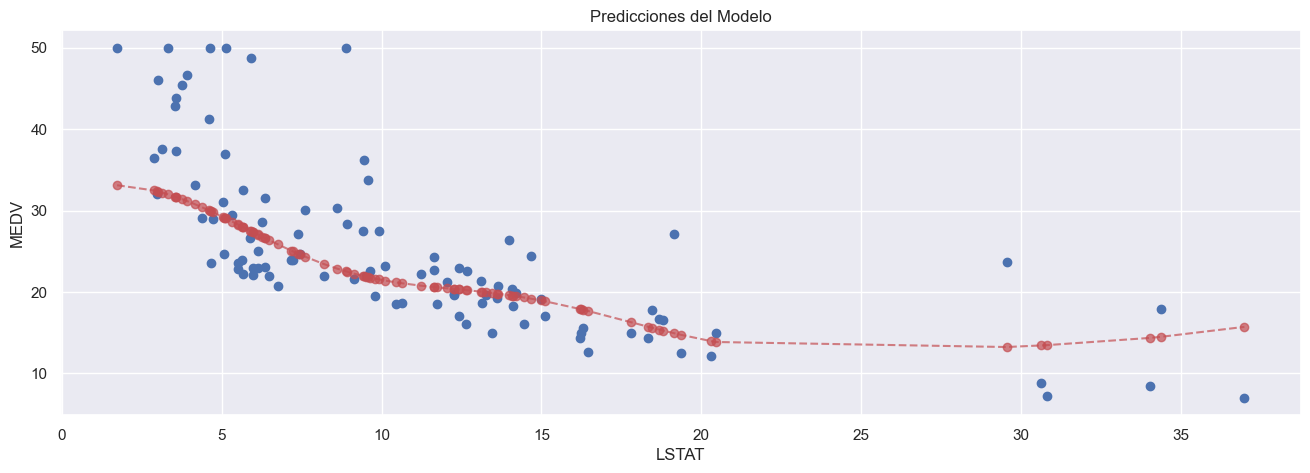

In [46]:
from sklearn.svm import SVR

print("Probando el SVM")
probar_modelo(SVR(), X_train, y_train, X_test, y_test)

Probando el DTR
Rendimiento del conjunto de Entrenamiento
RMSE: 1.5519310870685916
R2: 0.9687049957667602
Rendimiento del conjunto de Testeo
RMSE: 8.695233368537806
R2: 0.2770458386848019


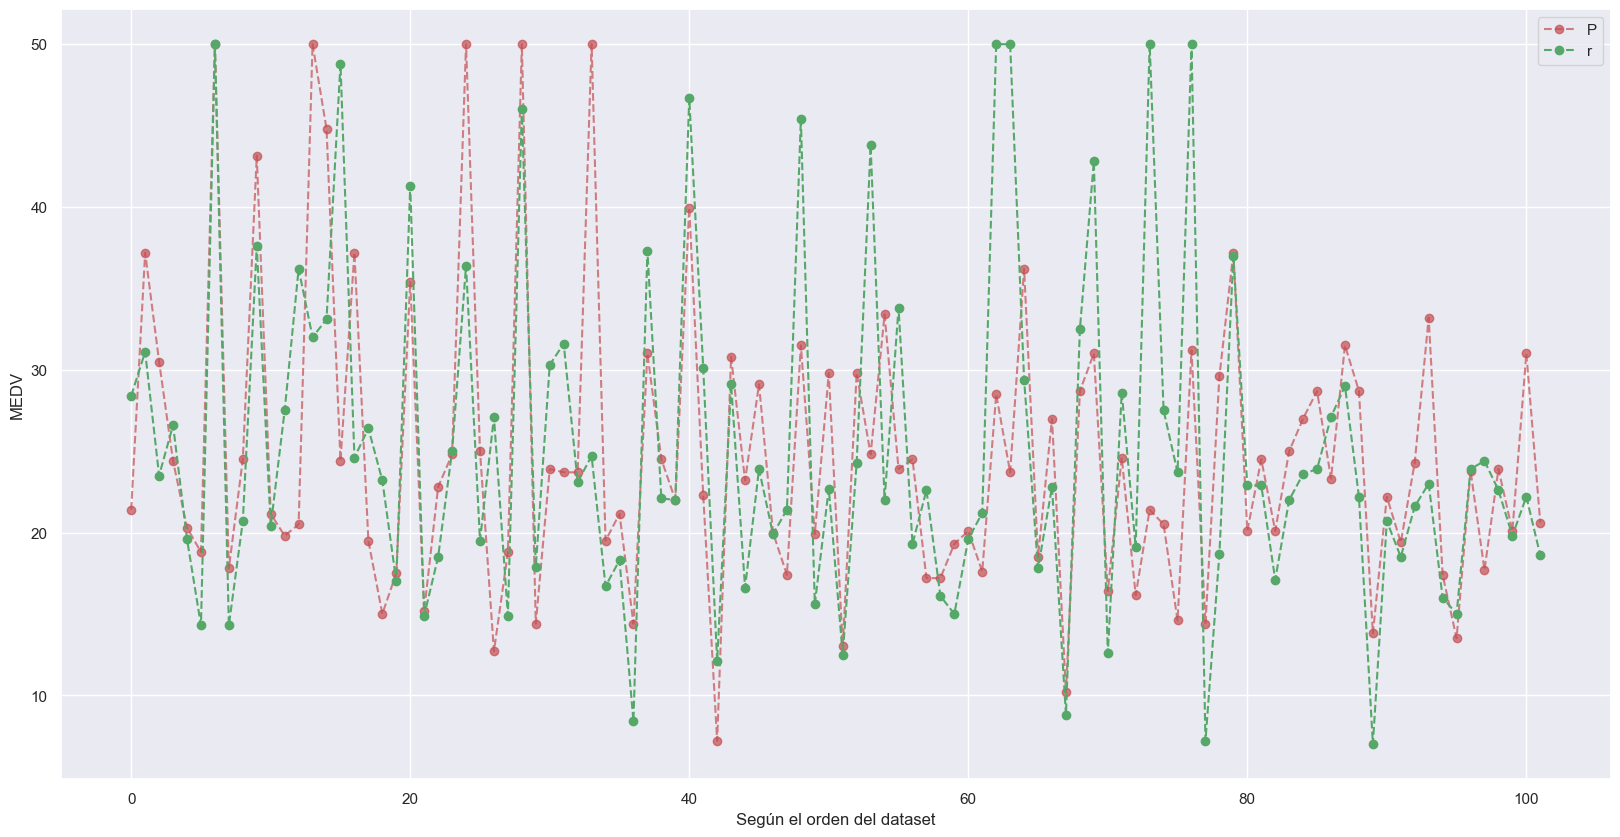

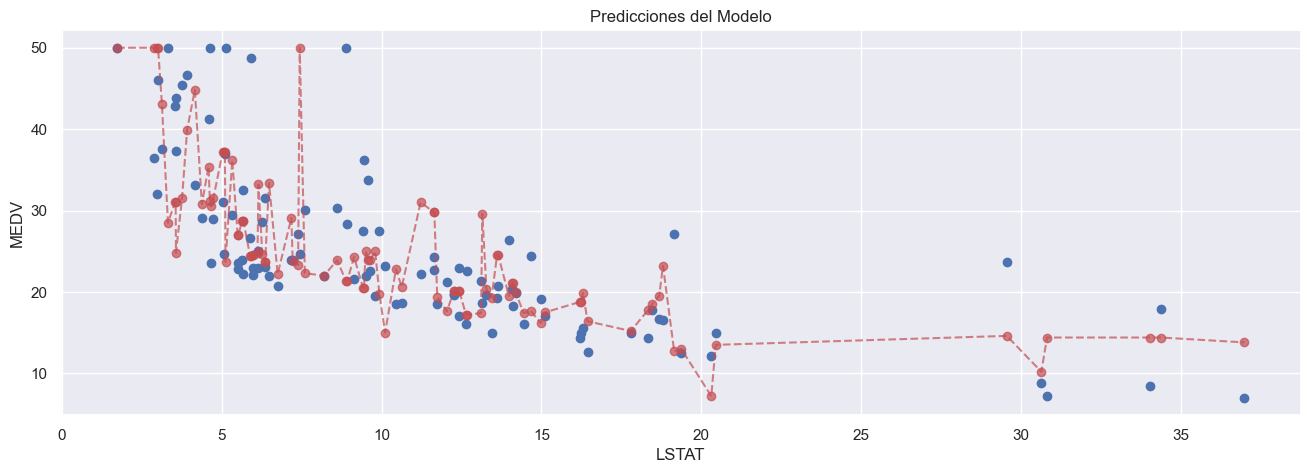

In [47]:
from sklearn.tree import DecisionTreeRegressor

print("Probando el DTR")
probar_modelo(DecisionTreeRegressor(), X_train, y_train, X_test, y_test)

Probando el Modelo KNN
Rendimiento del conjunto de Entrenamiento
RMSE: 4.435843652665307
R2: 0.7443283288082831
Rendimiento del conjunto de Testeo
RMSE: 6.568457603891317
R2: 0.5874514364376054


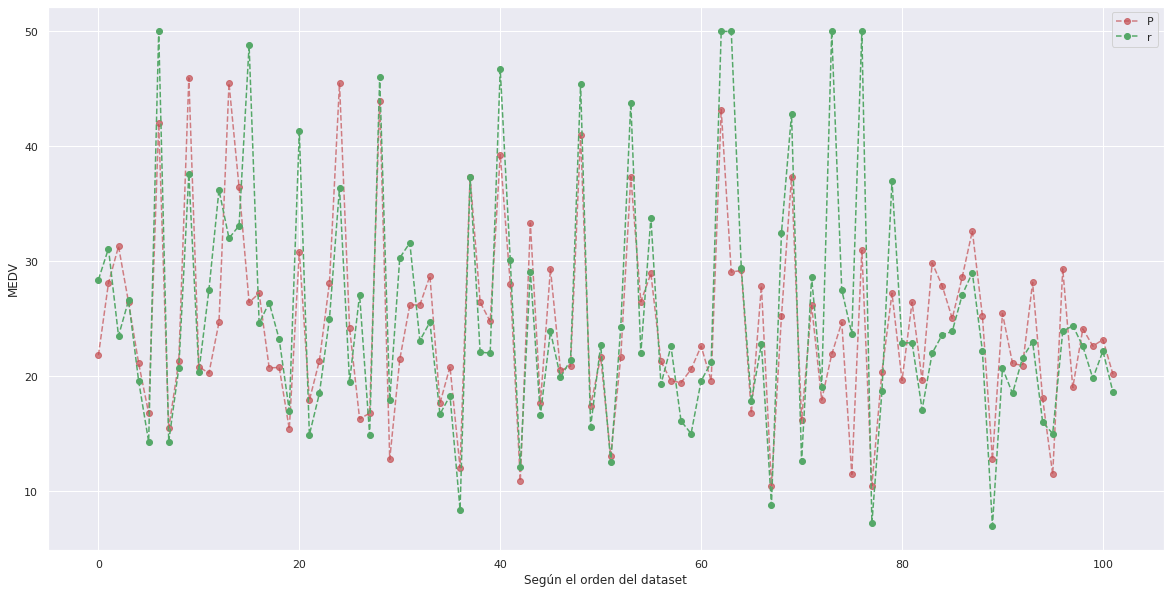

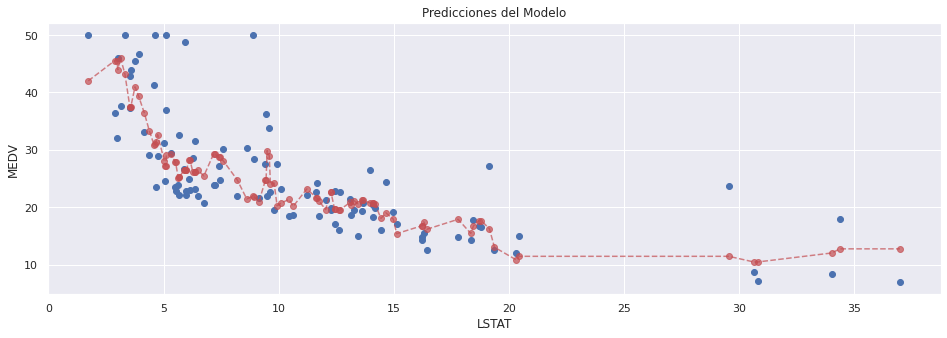

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

print("Probando el Modelo KNN")
probar_modelo(KNeighborsRegressor(), X_train, y_train, X_test, y_test)

Probando el Modelo GBR
Rendimiento del conjunto de Entrenamiento
RMSE: 3.6580438616346567
R2: 0.8261286739086469
Rendimiento del conjunto de Testeo
RMSE: 7.196571987098877
R2: 0.5047783474469738


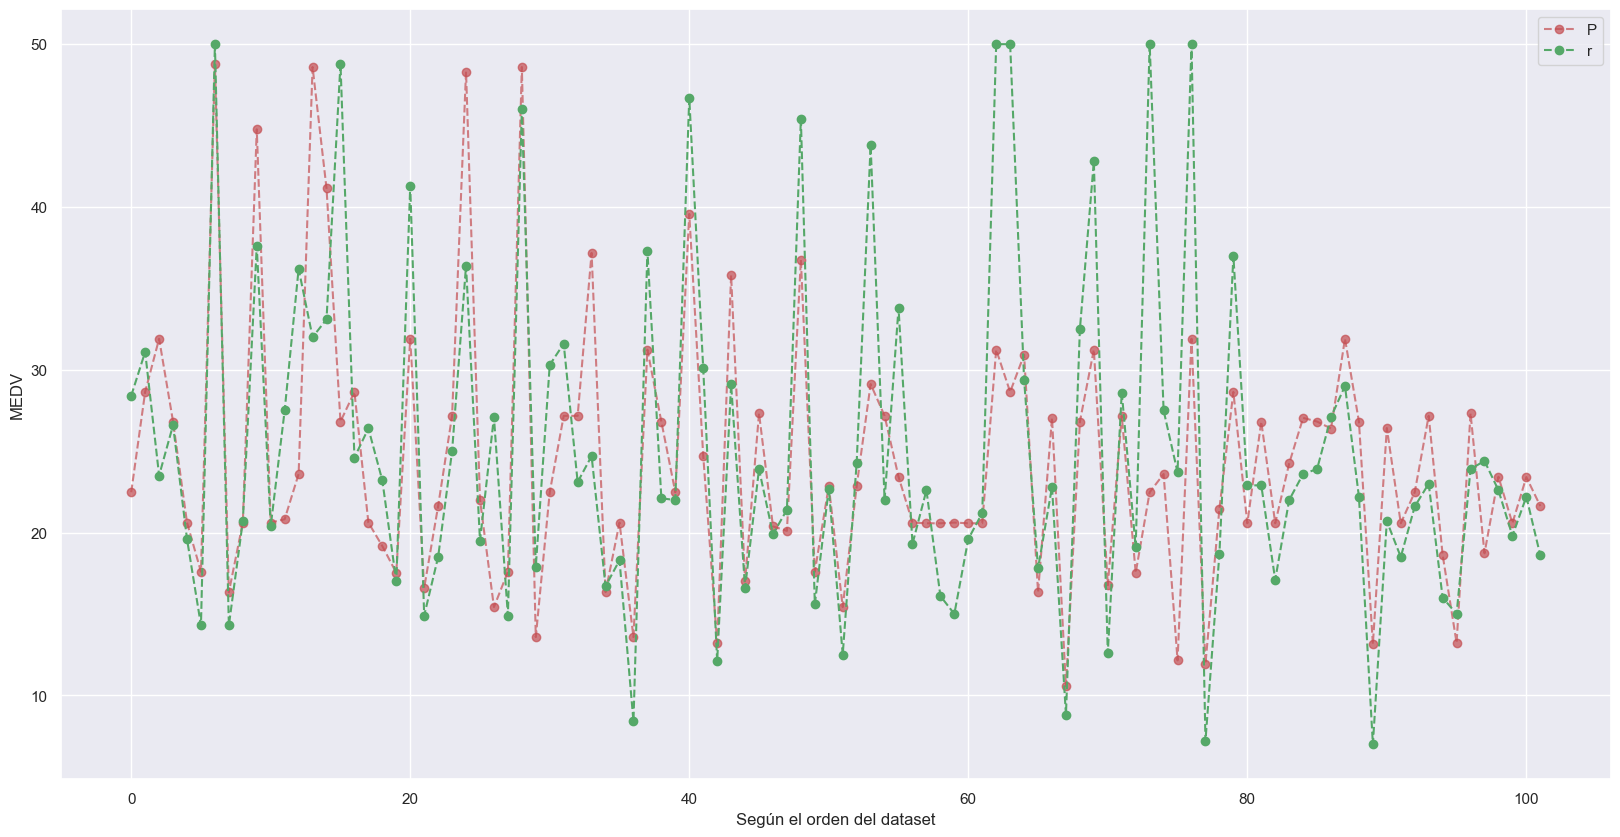

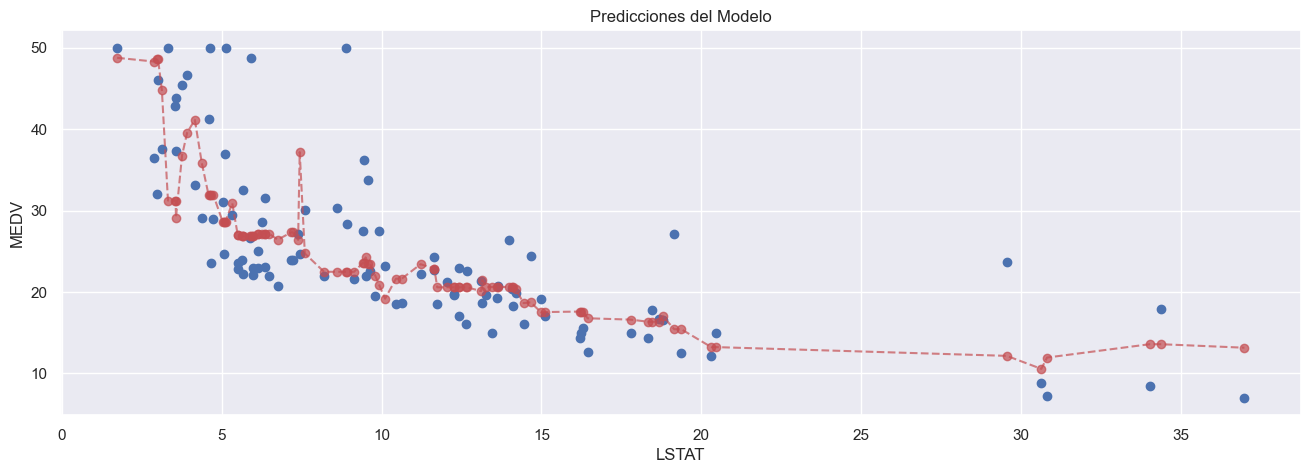

In [48]:
from sklearn.ensemble import GradientBoostingRegressor

print("Probando el Modelo GBR")
probar_modelo(GradientBoostingRegressor(), X_train, y_train, X_test, y_test)

Probando el Modelo Ada
Rendimiento del conjunto de Entrenamiento
RMSE: 4.549190153460733
R2: 0.7310953388777458
Rendimiento del conjunto de Testeo
RMSE: 6.591219759833295
R2: 0.5845872128745107


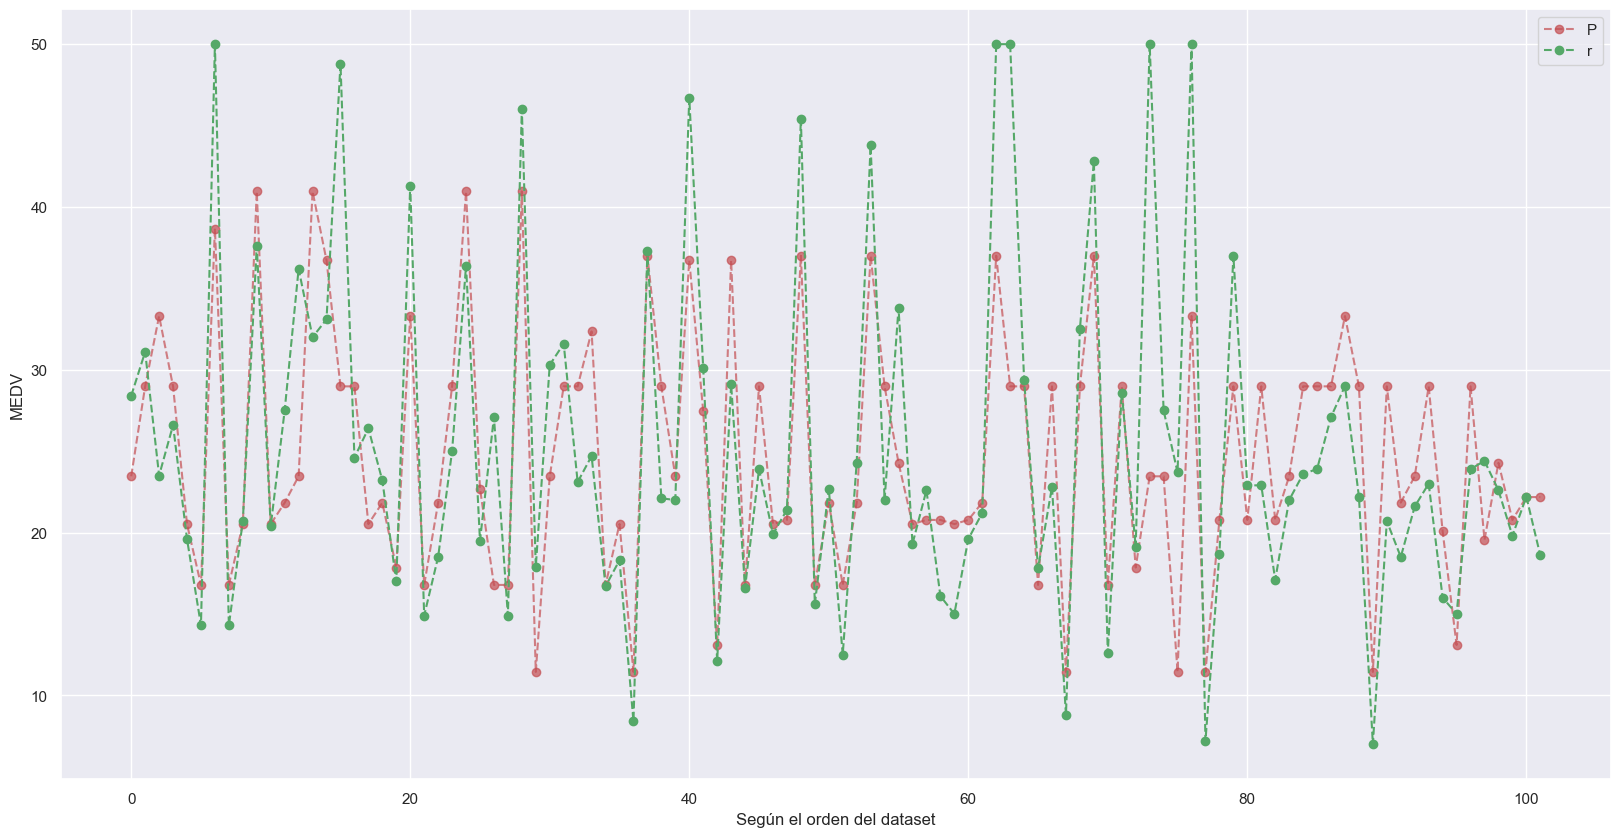

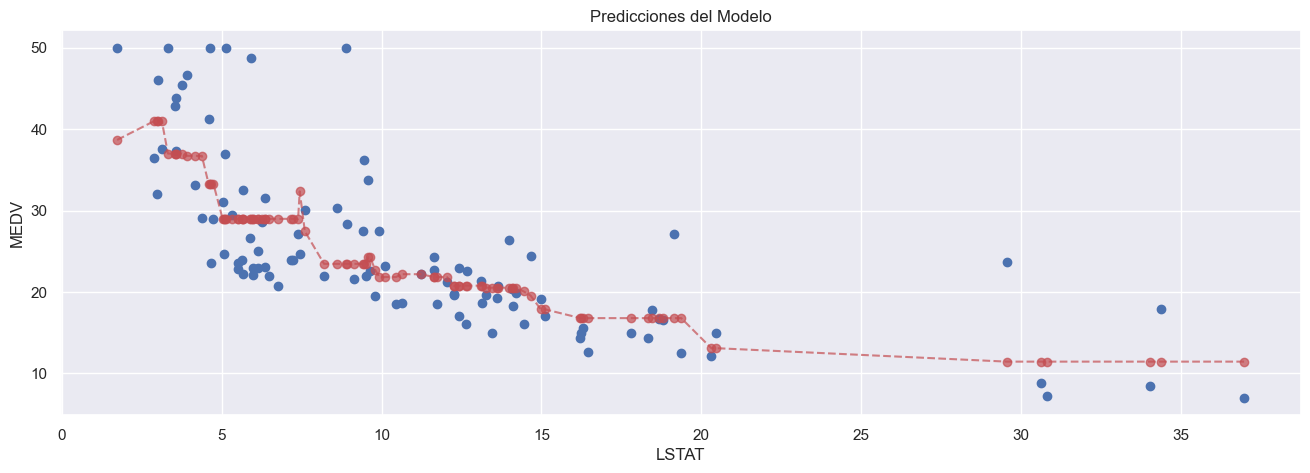

In [49]:
from sklearn.ensemble import AdaBoostRegressor

print("Probando el Modelo Ada")
probar_modelo(AdaBoostRegressor(), X_train, y_train, X_test, y_test)

In [50]:
#Validación cruzada entre los modelos
from sklearn.model_selection import cross_val_score

modelos = {}
modelos['LR_'] = LinearRegression()
modelos['Las'] = Lasso()
modelos['SVM'] = SVR()
modelos['DTR'] = DecisionTreeRegressor()
modelos['KNN'] = KNeighborsRegressor()
modelos['GBR'] = GradientBoostingRegressor()
modelos['Ada'] = AdaBoostRegressor()

resultados_modelos = []

print("Modelos\t\t Mean \t\t Std")

for modelo_a_probar in modelos:
  resultados = cross_val_score(modelos[modelo_a_probar], X_train, y_train, scoring = 'neg_mean_squared_error')
  resultados_modelos.append(resultados)
  print("{}\t\t: {}\t {}".format(modelo_a_probar, round(resultados.mean(), 3), round(resultados.std(), 3)))

NameError: name 'KNeighborsRegressor' is not defined

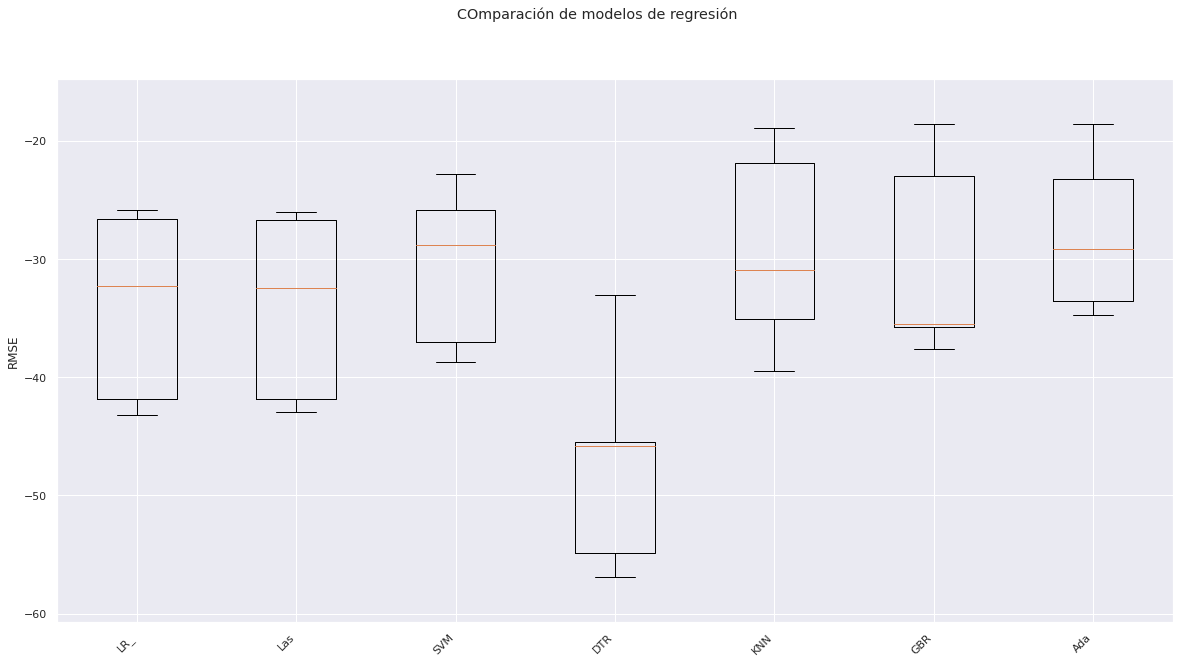

In [ ]:
#Graficar la comparación con velas/cajas

figura = plt.figure()
figura.suptitle('COmparación de modelos de regresión')
ejes = figura.add_subplot(111)

plt.boxplot(resultados_modelos)
ejes.set_xticklabels(modelos, rotation = 45, ha = "right")
ejes.set_ylabel("RMSE")
plt.margins(0.05, 0.1)
plt.show()